# Need detection: baselines vs. M1 vs. M2

Binary task: is this post a real need (`is_need`)? All numbers are **out-of-fold** on the same 543 labeled training posts, using the **same 5-fold grouped CV splits** for M1 and M2 (near-duplicates stay in one fold). **No test data is used here**; final numbers come from `labeling/test_final.csv`.

Produce the inputs first (from the repo root):
```
python src/train_m1.py
python src/train_m2.py            # GPU, ~5 min
python src/zeroshot_screen.py --ids data/processed/ids_train.csv --out data/processed/zeroshot_train.parquet
```

| | Model | Threshold |
|---|---|---|
| B0 | always "not a need" | — |
| B1 | keyword rule (`any_need`) | — |
| B2 | zero-shot BART-MNLI, off the shelf | ≥90% recall |
| M1 | TF-IDF + logistic regression | ≥90% recall |
| M2 | fine-tuned DistilRoBERTa, 3 epochs | ≥90% recall |

The ≥90%-recall threshold is chosen on the same out-of-fold scores, so precision/F1 at that threshold are mildly optimistic for B2/M1/M2 alike. PR-AUC does not depend on a threshold.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve, precision_recall_fscore_support
from IPython.display import Markdown, display

ROOT = Path.cwd(); P = ROOT / 'data/processed'; R = ROOT / 'reports'
df = pd.read_parquet(P / 'train_labels.parquet')
m1 = pd.read_parquet(R / 'm1_oof.parquet').rename(columns={'prob': 'M1'})
m2 = pd.read_parquet(R / 'm2_oof.parquet').rename(columns={'prob': 'M2'})
zs = pd.read_parquet(P / 'zeroshot_train.parquet')[['post_id', 'zs_need_score']].rename(columns={'zs_need_score': 'B2'})
d = (df.merge(m1[['post_id', 'M1']], on='post_id').merge(m2[['post_id', 'M2']], on='post_id')
       .merge(zs, on='post_id', how='left'))
d['B0'] = 0.0; d['B1'] = d['any_need'].astype(float)
assert len(d) == len(df) and d['B2'].notna().all(), 'missing predictions - run the three commands above'
y = d['is_need'].to_numpy(int)
print(f'{len(d)} posts | needs: {y.sum()} ({y.mean():.1%})')
display(Markdown((R / 'm2_cv.md').read_text()))
print((R / 'm2_log.txt').read_text())

543 posts | needs: 173 (31.9%)


# M2 cross-validation

5-fold grouped CV (same splits as M1), 3 epochs fixed.

Precision 0.473; recall 0.902; F1 0.620; PR-AUC 0.637; threshold 0.2567.


device=cuda; rows=543; folds=5; epochs=3
fold=1 val_n=109 val_pr_auc=0.753
fold=2 val_n=108 val_pr_auc=0.692
fold=3 val_n=109 val_pr_auc=0.561
fold=4 val_n=109 val_pr_auc=0.589
fold=5 val_n=108 val_pr_auc=0.723
oof precision=0.473 recall=0.902 f1=0.620 pr_auc=0.637 threshold=0.2567



In [2]:
def hr_threshold(y, p):
    ok = [t for t in np.unique(np.r_[0, p, 1]) if (p[y == 1] >= t).mean() >= .9]
    return max(ok) if ok else 0.0

MODELS = ['B0', 'B1', 'B2', 'M1', 'M2']
TH = {'B0': .5, 'B1': .5, **{m: hr_threshold(y, d[m].to_numpy()) for m in ['B2', 'M1', 'M2']}}
PRED = {m: (d[m].to_numpy() >= TH[m]).astype(int) for m in MODELS}

def scores(y, pred, prob):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
    return p, r, f, average_precision_score(y, prob) if y.any() else np.nan

rng = np.random.default_rng(0); B = 1000
boot_idx = [rng.integers(0, len(y), len(y)) for _ in range(B)]
rows = []
for m in MODELS:
    prob = d[m].to_numpy(); point = scores(y, PRED[m], prob)
    bs = np.array([scores(y[i], PRED[m][i], prob[i]) for i in boot_idx])
    lo, hi = np.nanpercentile(bs, 2.5, axis=0), np.nanpercentile(bs, 97.5, axis=0)
    rows.append({'model': m, 'threshold': round(TH[m], 3), **{f'{k}': f'{v:.3f} [{a:.2f}, {b:.2f}]' for k, v, a, b in zip(['precision', 'recall', 'F1', 'PR-AUC'], point, lo, hi)}})
print('Point estimate [bootstrap 95% CI], out-of-fold on 543 posts')
pd.DataFrame(rows).set_index('model')

Point estimate [bootstrap 95% CI], out-of-fold on 543 posts


,threshold,precision,recall,F1,PR-AUC
model,,,,,
B0,0.500,"0.000 [0.00, 0.00]","0.000 [0.00, 0.00]","0.000 [0.00, 0.00]","0.319 [0.28, 0.36]"
B1,0.500,"0.319 [0.28, 0.36]","1.000 [1.00, 1.00]","0.483 [0.44, 0.53]","0.319 [0.28, 0.36]"
B2,0.027,"0.327 [0.28, 0.37]","0.902 [0.85, 0.94]","0.480 [0.43, 0.53]","0.507 [0.43, 0.59]"
M1,0.431,"0.470 [0.41, 0.52]","0.902 [0.85, 0.94]","0.618 [0.56, 0.67]","0.653 [0.58, 0.73]"
M2,0.257,"0.473 [0.41, 0.53]","0.902 [0.86, 0.94]","0.620 [0.56, 0.67]","0.637 [0.56, 0.72]"


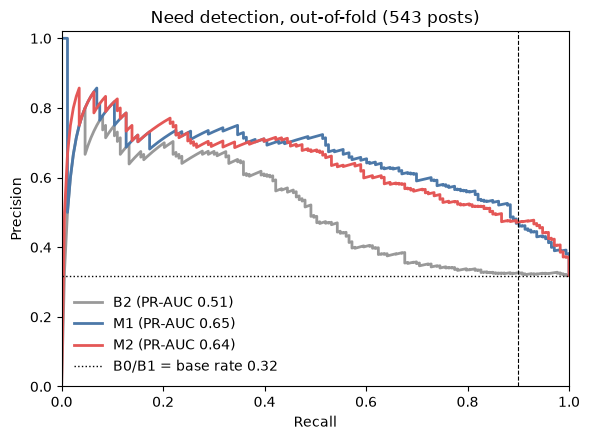

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for m, c in zip(['B2', 'M1', 'M2'], ['#999999', '#4C78A8', '#E45756']):
    pr, rc, _ = precision_recall_curve(y, d[m])
    ax.plot(rc, pr, color=c, lw=2, label=f'{m} (PR-AUC {average_precision_score(y, d[m]):.2f})')
ax.axhline(y.mean(), color='k', ls=':', lw=1, label=f'B0/B1 = base rate {y.mean():.2f}')
ax.axvline(.9, color='k', ls='--', lw=.8)
ax.set(xlabel='Recall', ylabel='Precision', title='Need detection, out-of-fold (543 posts)', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False, loc='lower left'); plt.tight_layout()
(R / 'figures').mkdir(exist_ok=True); fig.savefig(R / 'figures/pr_curve_need.png', dpi=150)

## Recall by subgroup (M1 vs. M2)

`n_need` is how many real needs each recall is computed on. Groups with fewer than ~20 needs have CIs too wide to say anything.

In [4]:
GROUPS = {'bay_local': d.sub_group.eq('bay_local'), 'housing_money': d.sub_group.eq('housing_money'), 'work': d.sub_group.eq('work'),
          'Bay Area (bay=True)': d.bay.astype(bool), 'national': ~d.bay.astype(bool),
          'short (<50 words)': d.n_words < 50, 'long (>=50 words)': d.n_words >= 50}

def recall_ci(yy, pp):
    pos = pp[yy == 1]
    if len(pos) == 0: return np.nan, np.nan, np.nan
    bs = [pos[rng.integers(0, len(pos), len(pos))].mean() for _ in range(B)]
    return pos.mean(), *np.percentile(bs, [2.5, 97.5])

out = []
for g, mask in GROUPS.items():
    mask = mask.to_numpy(); row = {'group': g, 'n_posts': int(mask.sum()), 'n_need': int(y[mask].sum())}
    for m in ['M1', 'M2']:
        r, lo, hi = recall_ci(y[mask], PRED[m][mask]); row[f'{m} recall'] = f'{r:.2f} [{lo:.2f}, {hi:.2f}]'
    out.append(row)
pd.DataFrame(out).set_index('group')

,n_posts,n_need,M1 recall,M2 recall
group,,,,
bay_local,294,71,"0.90 [0.83, 0.97]","0.90 [0.82, 0.96]"
housing_money,125,64,"0.91 [0.83, 0.97]","0.91 [0.83, 0.97]"
work,124,38,"0.89 [0.79, 0.97]","0.89 [0.79, 0.97]"
Bay Area (bay=True),303,73,"0.90 [0.84, 0.97]","0.90 [0.82, 0.96]"
national,240,100,"0.90 [0.84, 0.95]","0.90 [0.83, 0.95]"
short (<50 words),53,3,"0.67 [0.00, 1.00]","0.67 [0.00, 1.00]"
long (>=50 words),490,170,"0.91 [0.86, 0.95]","0.91 [0.86, 0.95]"


## Where M2 goes wrong

Most confident misses in each direction (out-of-fold). Internal use only — paraphrase before putting any of these on slides. Outputs are cleared in the public repo because they show real post text; re-run locally to see them.

In [ ]:
pd.set_option('display.max_colwidth', 220)
show = lambda x: x.assign(text=x.text.str.slice(0, 220))[['sub_group', 'M2', 'M1', 'text']].round(3)
print(f"False negatives (real need, M2 < {TH['M2']:.3f}): {int(((y == 1) & (PRED['M2'] == 0)).sum())}")
display(show(d[(y == 1) & (PRED['M2'] == 0)].sort_values('M2').head(6)))
print(f"False positives (not a need, M2 >= threshold): {int(((y == 0) & (PRED['M2'] == 1)).sum())}")
display(show(d[(y == 0) & (PRED['M2'] == 1)].sort_values('M2', ascending=False).head(6)))

## Known data issues (not fixable from this side)

1. **Every labeled post is a keyword hit** (`any_need` is True for all 543). The plan was 50% keyword hits + 50% random. So B1 flags everything here, and we cannot measure needs the keyword rule misses. Fix: label ~150 random non-keyword posts.
2. **No inter-annotator agreement yet.** `train_labels.parquet` holds 50 posts merged from two labelers (`person1+person2 (union)`), but the individual labels were merged before export. `build_dataset.py` now reports per-label Cohen's kappa when it is run on the raw `labeling/done/*.xlsx` files.
3. **Binary only.** No urgency labels and no multi-label need model in M2 yet; M1 has per-type TF-IDF models (see `reports/m1_cv.md`).
4. **Short posts:** only a handful of short posts are needs, so short-vs-long recall is not a usable fairness result.